# DSML Lab Assignment 1 — Gradient Descent as a Dynamical System

Run all cells from top to bottom (*Runtime → Run all*).

In the tables, **status** is the stop reason returned by the code (`converged`, `max_iter`, `safety_stop`, `nonfinite`), and **behavior** is what the math says happens. These are not the same thing, so I keep them in separate columns.

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def save(fig, name):
    """Save a figure to ./figures and show it."""
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=130)
    plt.show()


def md_table(headers, rows):
    """Show a list of rows as a table."""
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def vec(x, p=10):
    return "(" + ", ".join(f"{float(v):.{p}g}" for v in np.atleast_1d(x)) + ")"


def sci(x):
    return "0" if x == 0 else f"{x:.3e}"


def nz(a):
    """Replace exact zeros by NaN so they are left out on a log axis."""
    a = np.array(a, dtype=float)
    a[a == 0] = np.nan
    return a

---
## Problem 0: Conceptual overview

**a)** In $x_{k+1}=x_k-\eta\nabla f(x_k)$:
* $x_k$ is the **state**: the current parameters at step $k$.
* $\eta$ is the **learning rate**: how big each step is.
* $\nabla f(x_k)$ is the **gradient**. It points uphill, so we step in the opposite direction.
* $k$ is the **iteration counter**, which plays the role of (discrete) time.

The state space is $\mathbb R^d$ (all possible parameter vectors), and the evolution law is the map $F_\eta(x)=x-\eta\nabla f(x)$. The system is **autonomous** because, once $f$ and $\eta$ are fixed, the same rule is applied at every step; the rule does not depend on $k$.

**b)** A fixed point satisfies $x^*=x^*-\eta\nabla f(x^*)$, so $\eta\nabla f(x^*)=0$. Since $\eta>0$, this means $\nabla f(x^*)=0$.

A zero gradient does **not** always mean a minimum: $-x^2$ has a maximum at 0 and $x_1^2-x_2^2$ has a saddle point at the origin. Both are still fixed points of gradient descent.

*Remaining close* to $x^*$ (stability) means that if we start near $x^*$, we stay near it. *Converging* (asymptotic stability) means we also get closer and closer to $x^*$. These are different: at $\eta=1$ in Problems 1 and 2, the iterates stay at the same distance from $x^*$ forever but never reach it.

**c)** Number of trainable parameters (the dimension of the state):

| Problem | Input features | Parameters |
|---|---|---|
| Problem 1 | — | 1 ($x$) |
| Problem 2 | — | 2 ($x_1,x_2$) |
| Dataset 1 | 1 | 2 ($w,b$) |
| Dataset 2 | 2 | 3 ($w_1,w_2,b$) |

The intercept $b$ is also a parameter, so there is always one more parameter than input features.

### Gradient descent function

In [7]:
def gradient_descent(f, grad_f, x0, eta, tol=1e-6, max_iter=10000, max_norm=1e6):
    """Run x_{k+1} = x_k - eta * grad_f(x_k).

    tol=None -> comparison mode (exactly max_iter updates unless a safety check fires).
    Returns the parameter, loss and gradient-norm histories, the number of updates
    and the stop reason.
    """
    x = np.array(x0, dtype=float).reshape(-1).copy()        # always a float vector
    g = np.asarray(grad_f(x), dtype=float).reshape(-1)
    xs, losses, gnorms = [x.copy()], [float(f(x))], [float(np.linalg.norm(g))]

    def finite(x, loss, g):
        return np.all(np.isfinite(x)) and np.isfinite(loss) and np.all(np.isfinite(g))

    status, n_updates = None, 0
    if not finite(x, losses[0], g):
        status = "nonfinite"
    elif tol is not None and gnorms[0] < tol:                 # starting point already converged
        status = "converged"

    while status is None:
        if n_updates >= max_iter:
            status = "max_iter"
            break
        x = x - eta * g
        n_updates += 1
        loss = float(f(x))
        g = np.asarray(grad_f(x), dtype=float).reshape(-1)
        xs.append(x.copy())
        losses.append(loss)
        gnorms.append(float(np.linalg.norm(g)))
        if not finite(x, loss, g):
            status = "nonfinite"
        elif np.linalg.norm(x) > max_norm:
            status = "safety_stop"
        elif tol is not None and gnorms[-1] < tol:
            status = "converged"

    return {"x": np.array(xs), "loss": np.array(losses), "grad_norm": np.array(gnorms),
            "n_updates": n_updates, "status": status}


def converge(f, g, x0, eta):
    return gradient_descent(f, g, x0, eta, tol=1e-6, max_iter=10000)


def compare(f, g, x0, eta):
    return gradient_descent(f, g, x0, eta, tol=None, max_iter=40)

---
## Problem 1: Gradient descent in 1D

$f(x)=x^2+3x+2$, so $f'(x)=2x+3$. Setting $f'(x)=0$ gives $x^*=-1.5$ with $f(x^*)=-0.25$. Since $f''(x)=2>0$, this is the minimum.

In [8]:
f1 = lambda x: float(x[0] ** 2 + 3 * x[0] + 2)
g1 = lambda x: np.array([2 * x[0] + 3.0])
xs1 = -1.5
fs1 = f1([xs1])
print(f"x* = {xs1}, f(x*) = {fs1}, f'(x*) = {g1([xs1])[0]}")

x* = -1.5, f(x*) = -0.25, f'(x*) = 0.0


### Task 1.1: Descent path ($\eta=0.1$, $x_0=10$)

| η | x₀ | final x | f(x) | |f'(x)| | updates | status |
|---|---|---|---|---|---|---|
| 0.1 | 10 | -1.4999995039 | -0.25 | 9.921e-07 | 76 | converged |

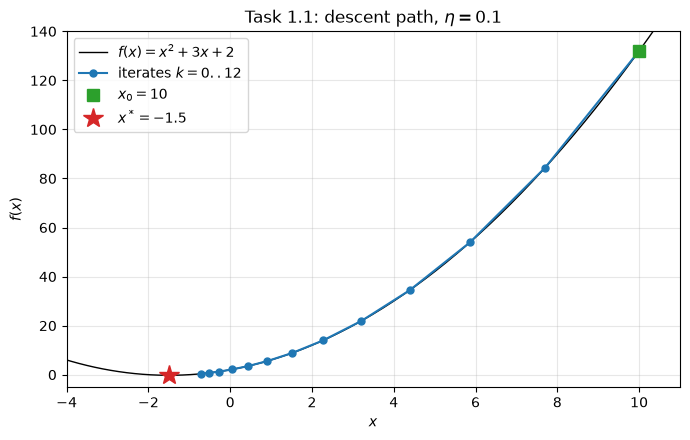

In [9]:
r11 = converge(f1, g1, [10.0], 0.1)
md_table(["η", "x₀", "final x", "f(x)", "|f'(x)|", "updates", "status"],
         [[0.1, 10, f"{r11['x'][-1, 0]:.10f}", f"{r11['loss'][-1]:.10g}", sci(r11['grad_norm'][-1]),
           r11["n_updates"], r11["status"]]])

xx = np.linspace(-14, 12, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(xx, xx ** 2 + 3 * xx + 2, "k-", lw=1, label="$f(x)=x^2+3x+2$")
p = r11["x"][:13, 0]                       # x_0 and the first 12 updates
ax.plot(p, p ** 2 + 3 * p + 2, "o-", color="tab:blue", ms=5, label="iterates $k=0..12$")
ax.plot(p[0], f1([p[0]]), "s", color="tab:green", ms=9, label="$x_0=10$")
ax.plot(xs1, fs1, "*", color="tab:red", ms=15, label="$x^*=-1.5$")
ax.set_xlim(-4, 11); ax.set_ylim(-5, 140)
ax.set_xlabel("$x$"); ax.set_ylabel("$f(x)$"); ax.set_title(r"Task 1.1: descent path, $\eta=0.1$")
ax.legend(); ax.grid(alpha=.3)
save(fig, "p1_task11_path.png")

### Task 1.2: Learning rate as a control parameter

**Changes:** $\eta$. **Fixed:** $f$ and $x_0=10$.

**a) Predictions** (using $e_{k+1}=(1-2\eta)\,e_k$ from Task 1.4, where $e_k=x_k-x^*$):

| $\eta$ | $1-2\eta$ | Prediction |
|---|---|---|
| 0.1 | 0.8 | approaches $x^*$ without crossing it |
| 0.5 | 0 | reaches $x^*$ in one step |
| 0.6 | −0.2 | oscillates around $x^*$, converges fast |
| 0.9 | −0.8 | oscillates around $x^*$, converges slowly |
| 1.0 | −1 | bounces between 10 and −13 forever |
| 1.1 | −1.2 | oscillates and moves away |

**b) Trajectories (40 updates).** The growing case $\eta=1.1$ is plotted separately.

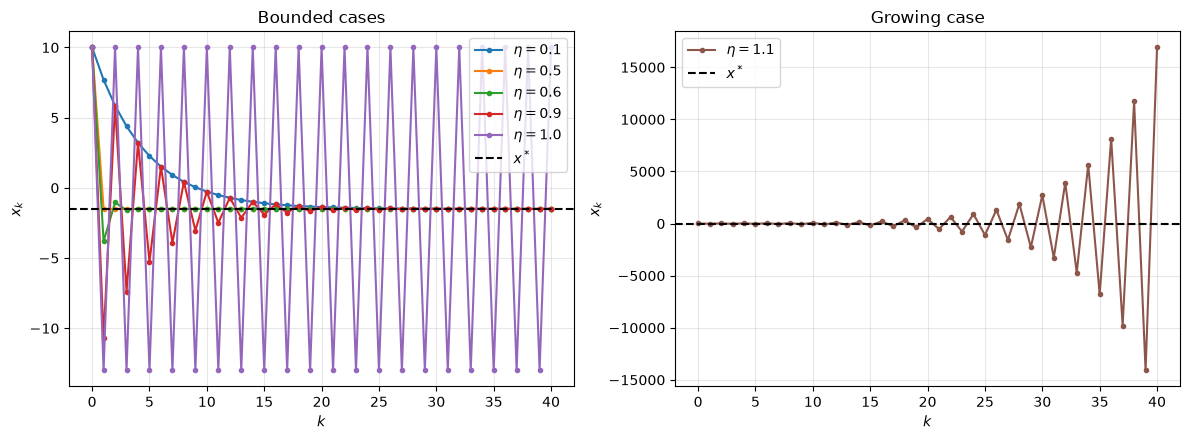

In [10]:
etas = [0.1, 0.5, 0.6, 0.9, 1.0, 1.1]
runs = {eta: compare(f1, g1, [10.0], eta) for eta in etas}
conv = {eta: converge(f1, g1, [10.0], eta) for eta in etas}

k = np.arange(41)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for eta in [0.1, 0.5, 0.6, 0.9, 1.0]:
    axs[0].plot(k, runs[eta]["x"][:, 0], "o-", ms=3, label=rf"$\eta={eta}$")
axs[0].axhline(xs1, color="k", ls="--", label="$x^*$")
axs[0].set_title("Bounded cases"); axs[0].set_xlabel("$k$"); axs[0].set_ylabel("$x_k$")
axs[0].legend(); axs[0].grid(alpha=.3)
axs[1].plot(k, runs[1.1]["x"][:, 0], "o-", ms=3, color="tab:brown", label=r"$\eta=1.1$")
axs[1].axhline(xs1, color="k", ls="--", label="$x^*$")
axs[1].set_title("Growing case"); axs[1].set_xlabel("$k$"); axs[1].set_ylabel("$x_k$")
axs[1].legend(); axs[1].grid(alpha=.3)
save(fig, "p1_task12_xk.png")

**c) Error on a log scale** (exact zeros left out), and the results table.

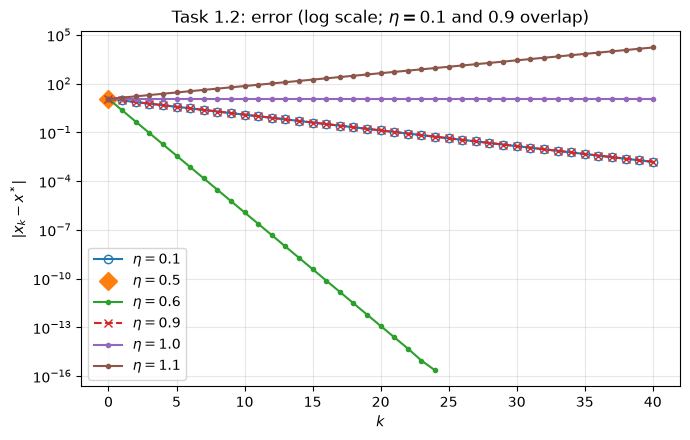

| η | x₀ | updates (40-run) | status (40-run) | final |f'| | final f | convergence run | behavior |
|---|---|---|---|---|---|---|---|
| 0.1 | 10 | 40 | max_iter | 3.057e-03 | -0.249998 | 76, converged | converges, no crossing |
| 0.5 | 10 | 40 | max_iter | 0 | -0.25 | 1, converged | converges in one step |
| 0.6 | 10 | 40 | max_iter | 0 | -0.25 | 11, converged | converges with oscillation |
| 0.9 | 10 | 40 | max_iter | 3.057e-03 | -0.249998 | 76, converged | converges with oscillation |
| 1.0 | 10 | 40 | max_iter | 2.300e+01 | 132 | 10000, max_iter | 2-cycle (bounded, no convergence) |
| 1.1 | 10 | 40 | max_iter | 3.380e+04 | 2.8569e+08 | 63, safety_stop | diverges with oscillation |

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
styles = {0.1: ("o-", 6), 0.5: ("D", 9), 0.6: ("o-", 3), 0.9: ("x--", 6), 1.0: ("o-", 3), 1.1: ("o-", 3)}
for eta in etas:
    st, ms = styles[eta]
    ax.semilogy(k, nz(np.abs(runs[eta]["x"][:, 0] - xs1)), st, ms=ms,
                mfc="none" if eta == 0.1 else None, label=rf"$\eta={eta}$")
ax.set_xlabel("$k$"); ax.set_ylabel(r"$|x_k-x^*|$")
ax.set_title(r"Task 1.2: error (log scale; $\eta=0.1$ and $0.9$ overlap)")
ax.legend(); ax.grid(alpha=.3, which="both")
save(fig, "p1_task12_error.png")

behavior1 = {0.1: "converges, no crossing", 0.5: "converges in one step", 0.6: "converges with oscillation",
             0.9: "converges with oscillation", 1.0: "2-cycle (bounded, no convergence)",
             1.1: "diverges with oscillation"}
rows = []
for eta in etas:
    rr, rc = runs[eta], conv[eta]
    rows.append([eta, 10, rr["n_updates"], rr["status"], sci(rr["grad_norm"][-1]),
                 f"{rr['loss'][-1]:.6g}", f"{rc['n_updates']}, {rc['status']}", behavior1[eta]])
md_table(["η", "x₀", "updates (40-run)", "status (40-run)", "final |f'|", "final f",
          "convergence run", "behavior"], rows)

All predictions are confirmed:
* $\eta=0.5$ lands exactly on $-1.5$ after one step.
* $\eta=1.0$ bounces between 10 and −13. Its convergence run ends with `max_iter`, but that does not mean it diverges: the orbit stays bounded.
* $\eta=1.1$ grows. The 40-update run stays below the safety limit; the longer run hits `safety_stop` after 63 updates. The safety stop is only a safeguard; the reason it diverges is that $|1-2\eta|=1.2>1$.

In [7]:
r = runs[0.9]
print("eta=0.9   x_k :", np.round(r["x"][:6, 0], 4))
print("eta=0.9 f(x_k):", np.round(r["loss"][:6], 4))

eta=0.9   x_k : [ 10.     -10.7      5.86    -7.388    3.2104  -5.2683]
eta=0.9 f(x_k): [132.      84.39    53.9196  34.4185  21.9379  13.9502]


**Does oscillation in $x_k$ mean $f(x_k)$ goes up?** No. $f(x)-f(x^*)=(x+1.5)^2$ only depends on the *distance* to $x^*$, not on which side we are on. For $\eta=0.9$, $x_k$ jumps from side to side, but the distance shrinks each step, so $f(x_k)$ keeps decreasing (see output above).

**Are $\eta=0.1$ and $\eta=0.9$ equally fast?** Yes. In both cases the distance to $x^*$ is multiplied by $0.8$ each step ($1-2\eta=0.8$ and $-0.8$). Their error curves lie on top of each other and both need 76 updates. The only difference is that $\eta=0.9$ alternates sides.

### Task 1.3: The role of the initial condition

**Changes:** $x_0\in\{10,-5,0\}$. **Fixed:** $f$, $\eta=0.1$.

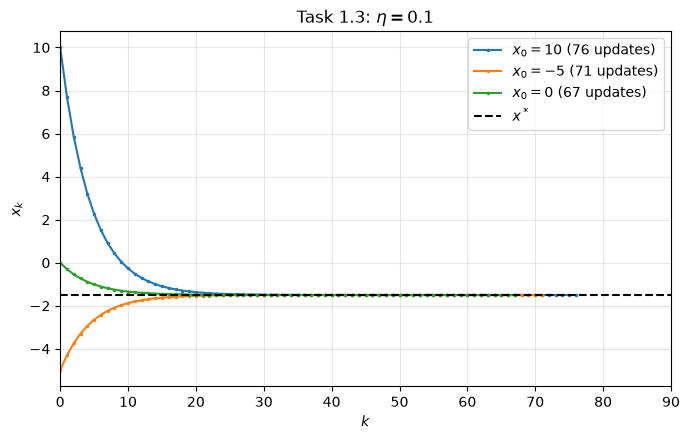

| η | x₀ | |x₀ − x*| | updates | status | final x | final |f'| | final f |
|---|---|---|---|---|---|---|---|
| 0.1 | 10.0 | 11.5 | 76 | converged | -1.4999995039 | 9.921e-07 | -0.25 |
| 0.1 | -5.0 | 3.5 | 71 | converged | -1.5000004607 | 9.215e-07 | -0.25 |
| 0.1 | 0.0 | 1.5 | 67 | converged | -1.4999995179 | 9.642e-07 | -0.25 |

In [8]:
rows = []
fig, ax = plt.subplots(figsize=(7, 4.5))
for x0 in [10.0, -5.0, 0.0]:
    rr = converge(f1, g1, [x0], 0.1)
    rows.append([0.1, x0, abs(x0 - xs1), rr["n_updates"], rr["status"], f"{rr['x'][-1, 0]:.10f}",
                 sci(rr["grad_norm"][-1]), f"{rr['loss'][-1]:.10g}"])
    ax.plot(rr["x"][:, 0], ".-", ms=3, label=f"$x_0={x0:g}$ ({rr['n_updates']} updates)")
ax.axhline(xs1, color="k", ls="--", label="$x^*$")
ax.set_xlim(0, 90); ax.set_xlabel("$k$"); ax.set_ylabel("$x_k$"); ax.set_title(r"Task 1.3: $\eta=0.1$")
ax.legend(); ax.grid(alpha=.3)
save(fig, "p1_task13_init.png")
md_table(["η", "x₀", "|x₀ − x*|", "updates", "status", "final x", "final |f'|", "final f"], rows)

All three runs reach the **same** minimizer, because $f$ has only one. Only the paths differ: $x_0=-5$ comes from the left, the other two from the right.

The number of updates depends on how far $x_0$ is from $x^*$: $x_0=10$ is the farthest (76 updates) and $x_0=0$ the closest (67). Because the error shrinks by a constant factor each step, the count grows only slowly with the distance.

### Task 1.4: Exact stability analysis

Let $e_k=x_k-x^*$. Since $2x^*+3=0$, we have $f'(x_k)=2x_k+3=2(x_k-x^*)=2e_k$. Subtracting $x^*$ from the update rule:
$$e_{k+1}=e_k-\eta\cdot 2e_k=(1-2\eta)\,e_k,\qquad\text{so}\qquad q(\eta)=1-2\eta,\quad e_k=(1-2\eta)^k e_0.$$

* $x^*$ is globally asymptotically stable when $|1-2\eta|<1$, i.e. **$0<\eta<1$**.
* **One-step case** $\eta=0.5$: $q=0$, so $x_1=x^*$ from any start.
* **Boundary case** $\eta=1$: $q=-1$, so the iterates bounce between two points at the same distance from $x^*$. The fixed point is **stable but not attracting**.
* For $\eta>1$: $|q|>1$, so $x^*$ is **unstable**.

**Why starting at $x^*$ stays at $x^*$ even when it is unstable:** the gradient at $x^*$ is zero, so the update does not move it, whatever $\eta$ is. "Unstable" only means that a small nudge away from $x^*$ grows.

---
## Problem 2: Gradient descent in 2D

$f(x_1,x_2)=x_1^2+x_2^2+3x_1+4x_2+5$. Setting both partial derivatives $2x_1+3$ and $2x_2+4$ to zero gives the minimizer $x^*=(-1.5,-2)$ with $f(x^*)=-1.25$.

In [9]:
f2 = lambda x: float(x[0] ** 2 + x[1] ** 2 + 3 * x[0] + 4 * x[1] + 5)
g2 = lambda x: np.array([2 * x[0] + 3.0, 2 * x[1] + 4.0])
xs2 = np.array([-1.5, -2.0])
print(f"x* = {xs2}, f(x*) = {f2(xs2)}, grad f(x*) = {g2(xs2)}")

X1g, X2g = np.meshgrid(np.linspace(-10, 7, 300), np.linspace(-10, 7, 300))
Z2 = X1g ** 2 + X2g ** 2 + 3 * X1g + 4 * X2g + 5
levels2 = np.linspace(f2(xs2), 140, 20)        # same levels for every contour plot


def contour_axes(ax, title):
    ax.contour(X1g, X2g, Z2, levels=levels2, cmap="viridis", linewidths=.8)
    ax.plot(*xs2, "*", color="tab:red", ms=15, label=r"$x^*$", zorder=5)
    ax.set_xlim(-10, 7); ax.set_ylim(-10, 7); ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title(title)

x* = [-1.5 -2. ], f(x*) = -1.25, grad f(x*) = [0. 0.]


### Task 2.1: Contour trajectory ($\eta=0.1$, $x_0=(5,5)$)

| η | x₀ | final x | f | ‖∇f‖ | updates | status |
|---|---|---|---|---|---|---|
| 0.1 | (5, 5) | (-1.49999972, -1.999999698) | -1.25 | 8.241e-07 | 76 | converged |

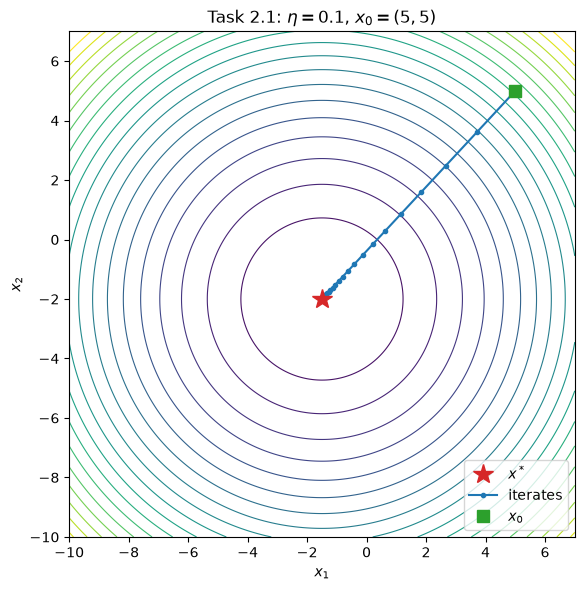

In [10]:
r21 = converge(f2, g2, [5.0, 5.0], 0.1)
md_table(["η", "x₀", "final x", "f", "‖∇f‖", "updates", "status"],
         [[0.1, "(5, 5)", vec(r21["x"][-1]), f"{r21['loss'][-1]:.10g}", sci(r21["grad_norm"][-1]),
           r21["n_updates"], r21["status"]]])

fig, ax = plt.subplots(figsize=(6, 6))
contour_axes(ax, r"Task 2.1: $\eta=0.1$, $x_0=(5,5)$")
ax.plot(r21["x"][:, 0], r21["x"][:, 1], "o-", ms=3, color="tab:blue", label="iterates")
ax.plot(5, 5, "s", color="tab:green", ms=9, label=r"$x_0$")
ax.legend(loc="lower right")
save(fig, "p2_task21_contour.png")

### Task 2.2: Different learning rates

**Changes:** $\eta\in\{0.1,0.5,1.0\}$. **Fixed:** $f$, $x_0=(5,5)$, contour levels and axis limits.

**Prediction** (same factor $1-2\eta$ as in 1D, see Task 2.4):
* $\eta=0.1$: straight, steady convergence.
* $\eta=0.5$: reaches $x^*$ in one step.
* $\eta=1.0$: jumps to $(-8,-9)$ and back to $(5,5)$ forever.

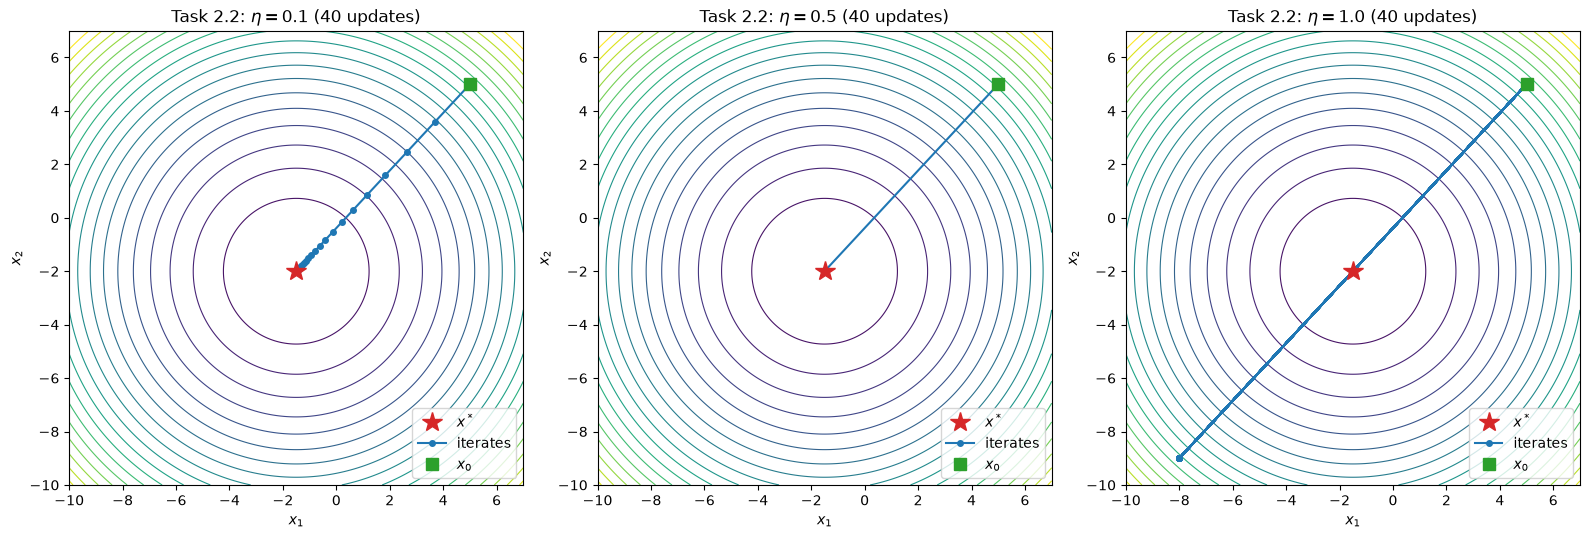

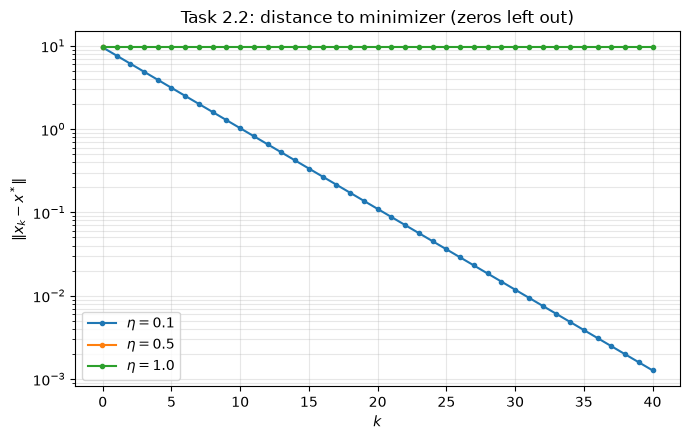

| η | x₀ | updates (40-run) | status (40-run) | final ‖∇f‖ | final f | convergence run | fixed-point classification |
|---|---|---|---|---|---|---|---|
| 0.1 | (5, 5) | 40 | max_iter | 2.539e-03 | -1.25 | 76, converged | asymptotically stable |
| 0.5 | (5, 5) | 40 | max_iter | 0 | -1.25 | 1, converged | asymptotically stable |
| 1.0 | (5, 5) | 40 | max_iter | 1.910e+01 | 90 | 10000, max_iter | stable but not attracting |

In [11]:
etas2 = [0.1, 0.5, 1.0]
runs2 = {eta: compare(f2, g2, [5.0, 5.0], eta) for eta in etas2}
conv2 = {eta: converge(f2, g2, [5.0, 5.0], eta) for eta in etas2}

fig, axs = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, eta in zip(axs, etas2):
    rr = runs2[eta]
    contour_axes(ax, rf"Task 2.2: $\eta={eta}$ (40 updates)")
    ax.plot(rr["x"][:, 0], rr["x"][:, 1], "o-", ms=4, color="tab:blue", label="iterates")
    ax.plot(5, 5, "s", color="tab:green", ms=9, label=r"$x_0$")
    ax.legend(loc="lower right")
save(fig, "p2_task22_contours.png")

fig, ax = plt.subplots(figsize=(7, 4.5))
for eta in etas2:
    ax.semilogy(np.arange(41), nz(np.linalg.norm(runs2[eta]["x"] - xs2, axis=1)), "o-", ms=3,
                label=rf"$\eta={eta}$")
ax.set_xlabel("$k$"); ax.set_ylabel(r"$\|x_k-x^*\|$")
ax.set_title("Task 2.2: distance to minimizer (zeros left out)"); ax.legend(); ax.grid(alpha=.3, which="both")
save(fig, "p2_task22_error.png")

classif2 = {0.1: "asymptotically stable", 0.5: "asymptotically stable",
            1.0: "stable but not attracting"}
rows = []
for eta in etas2:
    rr, rc = runs2[eta], conv2[eta]
    rows.append([eta, "(5, 5)", rr["n_updates"], rr["status"], sci(rr["grad_norm"][-1]),
                 f"{rr['loss'][-1]:.6g}", f"{rc['n_updates']}, {rc['status']}", classif2[eta]])
md_table(["η", "x₀", "updates (40-run)", "status (40-run)", "final ‖∇f‖", "final f",
          "convergence run", "fixed-point classification"], rows)

**Does a bounded orbit have to converge?** No. At $\eta=1$ the iterates stay at the same distance (about 9.55) from $x^*$ forever, jumping between $(5,5)$ and $(-8,-9)$. They are bounded but never converge.

The classification in the table comes from the factor $1-2\eta$ derived in Task 2.4 (0.8, 0 and −1), so it holds for every starting point, not only for $(5,5)$.

### Task 2.3: Different starting points

**Changes:** $x_0\in\{(5,5),(-5,5),(-5,-5)\}$. **Fixed:** $f$, $\eta=0.1$.

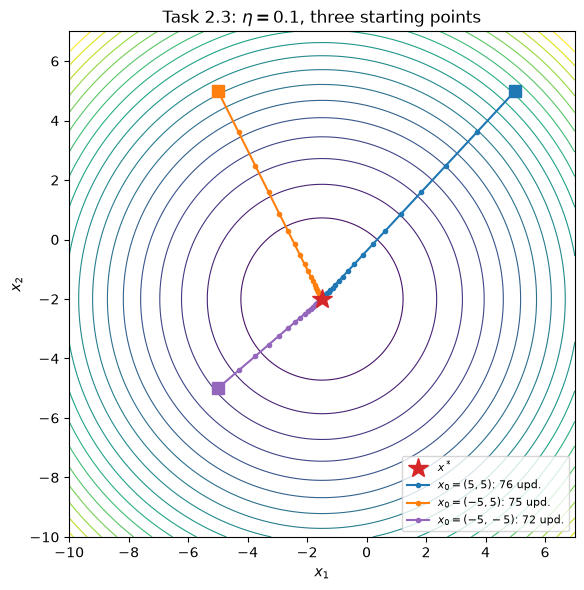

| η | x₀ | ‖x₀ − x*‖ | updates | status | final x | final ‖∇f‖ | final f |
|---|---|---|---|---|---|---|---|
| 0.1 | (5, 5) | 9.5525 | 76 | converged | (-1.49999972, -1.999999698) | 8.241e-07 | -1.25 |
| 0.1 | (-5, 5) | 7.8262 | 75 | converged | (-1.500000189, -1.999999623) | 8.440e-07 | -1.25 |
| 0.1 | (-5, -5) | 4.6098 | 72 | converged | (-1.500000369, -2.000000316) | 9.709e-07 | -1.25 |

In [12]:
rows = []
fig, ax = plt.subplots(figsize=(6, 6))
contour_axes(ax, r"Task 2.3: $\eta=0.1$, three starting points")
for x0, c in zip([(5, 5), (-5, 5), (-5, -5)], ["tab:blue", "tab:orange", "tab:purple"]):
    rr = converge(f2, g2, x0, 0.1)
    rows.append([0.1, str(x0), f"{np.linalg.norm(np.array(x0, float) - xs2):.4f}", rr["n_updates"],
                 rr["status"], vec(rr["x"][-1]), sci(rr["grad_norm"][-1]), f"{rr['loss'][-1]:.10g}"])
    ax.plot(rr["x"][:, 0], rr["x"][:, 1], "o-", ms=3, color=c, label=f"$x_0={x0}$: {rr['n_updates']} upd.")
    ax.plot(*x0, "s", color=c, ms=8)
ax.legend(loc="lower right", fontsize=8)
save(fig, "p2_task23_inits.png")
md_table(["η", "x₀", "‖x₀ − x*‖", "updates", "status", "final x", "final ‖∇f‖", "final f"], rows)

All three runs end at the same minimizer $(-1.5,-2)$. Each one comes in along its own straight line, so the **direction of approach** changes. The **number of updates** also changes a little (76, 75, 72), depending on how far the starting point is from $x^*$. So initialization changes the direction and the update count, but **not** the limit.

### Task 2.4: Stability, curvature and the shape of the path

The Hessian is $H=\begin{pmatrix}2&0\\0&2\end{pmatrix}=2I$, so the Jacobian of the update is $DF_\eta=I-\eta H=(1-2\eta)I$.

Since $\nabla f(x^*)=0$ and the gradient is linear, $\nabla f(x_k)=H(x_k-x^*)=He_k$. Subtracting $x^*$ from the update rule gives
$$e_{k+1}=e_k-\eta He_k=(I-\eta H)\,e_k.$$

* Both eigenvalues of $I-\eta H$ equal $1-2\eta$, so it converges when $|1-2\eta|<1$, i.e. **$0<\eta<1$**. This gives the classifications of Task 2.2: $\eta=0.1$ and $0.5$ are inside, $\eta=1$ is the boundary.
* **No higher-order remainder** is needed because $f$ is quadratic, so its gradient is exactly linear. The relation above is exact, not an approximation.
* **Straight line:** $e_k=(1-2\eta)^k e_0$ is always a multiple of $e_0$, so every iterate lies on the line through $x_0$ and $x^*$.
* **Do alternating iterates stay between $x_0$ and $x^*$?** No. When $1-2\eta<0$ the multiple is negative every other step, so the iterate lands on the *other side* of $x^*$. For $\eta=1$, $x_1=(-8,-9)$ is on the line but outside the segment.

In [13]:
H2 = np.array([[2.0, 0.0], [0.0, 2.0]])
for eta in etas2:
    print(f"eta={eta}: eigenvalues of I - eta*H = {np.linalg.eigvalsh(np.eye(2) - eta * H2)}")
print("eta=1.0 first states:", runs2[1.0]["x"][:4].tolist())

eta=0.1: eigenvalues of I - eta*H = [0.8 0.8]
eta=0.5: eigenvalues of I - eta*H = [0. 0.]
eta=1.0: eigenvalues of I - eta*H = [-1. -1.]
eta=1.0 first states: [[5.0, 5.0], [-8.0, -9.0], [5.0, 5.0], [-8.0, -9.0]]


---
## Problem 3: Linear regression

The data are fixed; what changes over the iterations is the coefficient vector $\theta$.

### Dataset 1: one input feature, two parameters

#### Task 3A.1: Parameter updates

With residuals $r_i=wx_i+b-y_i$ and $L=\frac1n\sum r_i^2$:
$$\frac{\partial L}{\partial w}=\frac2n\sum_i r_ix_i,\qquad\frac{\partial L}{\partial b}=\frac2n\sum_i r_i .$$
The updates are $w\leftarrow w-\eta\,\partial L/\partial w$ and $b\leftarrow b-\eta\,\partial L/\partial b$, both computed from the **same** current residuals (simultaneous update). In the code this is written as $\frac2nA^\top(A\theta-y)$.

In [14]:
X = np.array([1, 2, 3, 4, 5], dtype=float)
Y = np.array([2, 4, 6, 8, 10], dtype=float)
n = len(X)
A1 = np.column_stack([X, np.ones(n)])


def mse_loss(A, y):
    return lambda th: float(np.mean((A @ th - y) ** 2))


def mse_grad(A, y):
    # residuals r = A th - y, gradient = (2/n) A^T r  (all coefficients use the same residuals)
    return lambda th: (2.0 / len(y)) * A.T @ (A @ th - y)


L1, G1 = mse_loss(A1, Y), mse_grad(A1, Y)

#### Task 3A.2: Learning rate from the curvature

With $A=[X\;\;\mathbf 1]$ we get $\hat y=A\theta$, $L(\theta)=\frac1n\|A\theta-y\|^2$ and $H=\frac2nA^\top A=\begin{pmatrix}22&6\\6&2\end{pmatrix}$.

In [15]:
H1 = 2 / n * A1.T @ A1
lam1 = np.linalg.eigvalsh(H1)
eta1 = 1 / lam1.max()
print("H =", H1.tolist())
print("eigenvalues of H =", lam1)
print(f"eta = 1/lambda_max = {eta1:.10f}")
print(f"upper bound 2/lambda_max = {2 / lam1.max():.10f}")

H = [[22.0, 6.0], [6.0, 2.0]]
eigenvalues of H = [ 0.33809621 23.66190379]
eta = 1/lambda_max = 0.0422620263
upper bound 2/lambda_max = 0.0845240526


As in Problem 2, gradient descent is stable when $|1-\eta\lambda|<1$ for every eigenvalue, which means $\eta<2/\lambda_{\max}\approx0.0845$. The choice $\eta=1/\lambda_{\max}\approx0.0423$ is halfway inside this interval, so it is stable.

In [16]:
r3a = converge(L1, G1, [0.0, 0.0], eta1)
w, b = r3a["x"][-1]
md_table(["η", "θ₀", "w", "b", "MSE", "‖∇L‖", "updates", "status"],
         [[f"{eta1:.7f}", "(0, 0)", f"{w:.10f}", sci(b), sci(r3a["loss"][-1]), sci(r3a["grad_norm"][-1]),
           r3a["n_updates"], r3a["status"]]])

| η | θ₀ | w | b | MSE | ‖∇L‖ | updates | status |
|---|---|---|---|---|---|---|---|
| 0.0422620 | (0, 0) | 1.9999992217 | 2.810e-06 | 1.437e-12 | 9.858e-07 | 842 | converged |

**Expected fit:** the data satisfy $y=2x$ exactly, so we expect $w=2$, $b=0$ and MSE $=0$. Gradient descent gets this up to about $10^{-6}$.

**Prediction for $\eta=0.1$** (**changes:** $\eta$; **fixed:** data and $\theta_0$): $0.1$ is above the bound $0.0845$, so the run should blow up.

In [17]:
r3a_bad = compare(L1, G1, [0.0, 0.0], 0.1)
md_table(["η", "θ₀", "updates", "status (40-run)", "final ‖∇L‖", "final MSE", "behavior"],
         [[0.1, "(0, 0)", r3a_bad["n_updates"], r3a_bad["status"], sci(r3a_bad["grad_norm"][-1]),
           sci(r3a_bad["loss"][-1]), "diverges"]])
print("MSE at k = 0, 10, 20, 30, 40:", r3a_bad["loss"][[0, 10, 20, 30, 40]])

| η | θ₀ | updates | status (40-run) | final ‖∇L‖ | final MSE | behavior |
|---|---|---|---|---|---|---|
| 0.1 | (0, 0) | 40 | max_iter | 1.201e+07 | 3.047e+12 | diverges |

MSE at k = 0, 10, 20, 30, 40: [4.40000000e+01 2.25528676e+04 1.15724618e+07 5.93813694e+09
 3.04701548e+12]


The MSE grows from 44 to about $3\times10^{12}$. The status is still `max_iter` because the parameters have not yet reached the $10^6$ safety limit, but the run is clearly diverging.

**Why $\eta=0.1$ worked before but not here:** what matters is $\eta$ times the curvature. In Problems 1 and 2 the curvature was 2, so any $\eta<1$ worked. Here the inputs go up to 5, which makes the largest curvature about 23.7, so $\eta$ must be below about 0.085.

#### Task 3A.3: Visualize and validate

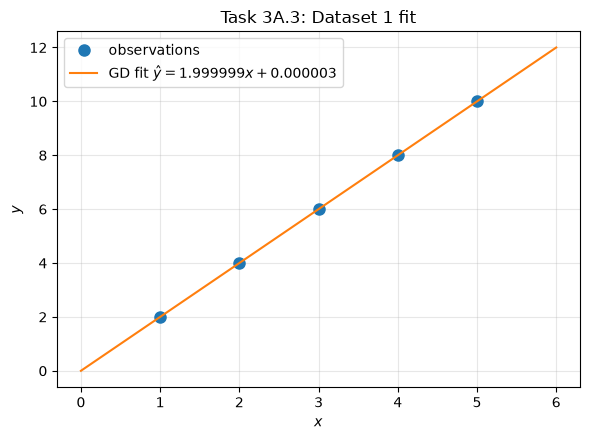

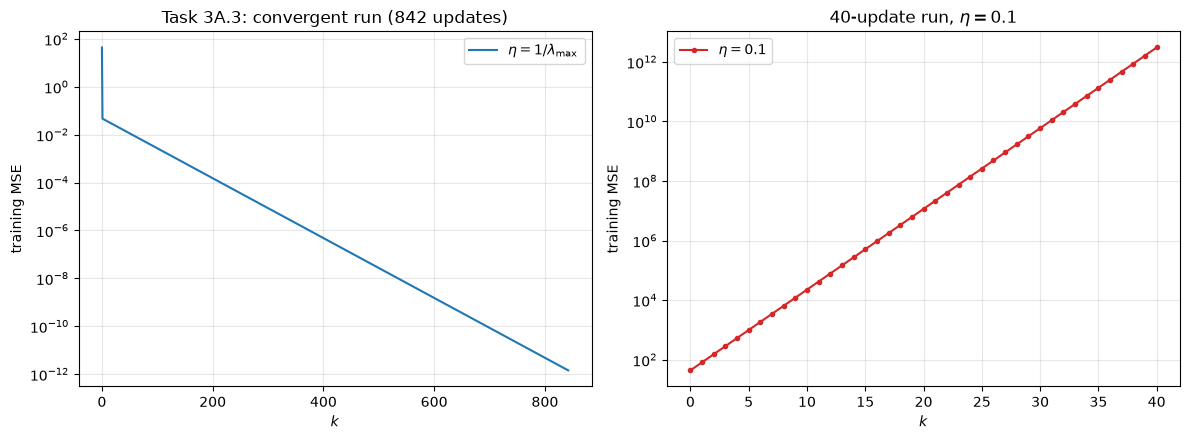

|  | w | b | MSE |
|---|---|---|---|
| gradient descent | 1.9999992217 | 2.810e-06 | 1.437e-12 |
| np.linalg.lstsq | 2.0000000000 | 1.005e-16 | 9.959e-31 |
| difference | 7.783e-07 | 2.810e-06 | 1.437e-12 |

In [18]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(X, Y, "o", ms=8, label="observations")
xl = np.linspace(0, 6, 50)
ax.plot(xl, w * xl + b, "-", label=rf"GD fit $\hat y={w:.6f}x{b:+.6f}$")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_title("Task 3A.3: Dataset 1 fit"); ax.legend(); ax.grid(alpha=.3)
save(fig, "p3a_fit.png")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].semilogy(nz(r3a["loss"]), "-", label=r"$\eta=1/\lambda_{\max}$")
axs[0].set_xlabel("$k$"); axs[0].set_ylabel("training MSE")
axs[0].set_title(f"Task 3A.3: convergent run ({r3a['n_updates']} updates)")
axs[0].grid(alpha=.3, which="both"); axs[0].legend()
axs[1].semilogy(r3a_bad["loss"], "o-", ms=3, color="tab:red", label=r"$\eta=0.1$")
axs[1].set_xlabel("$k$"); axs[1].set_ylabel("training MSE"); axs[1].set_title(r"40-update run, $\eta=0.1$")
axs[1].grid(alpha=.3, which="both"); axs[1].legend()
save(fig, "p3a_loss.png")

theta_ref = np.linalg.lstsq(A1, Y, rcond=None)[0]
mse_ref = np.mean((A1 @ theta_ref - Y) ** 2)
md_table(["", "w", "b", "MSE"],
         [["gradient descent", f"{w:.10f}", sci(b), sci(r3a["loss"][-1])],
          ["np.linalg.lstsq", f"{theta_ref[0]:.10f}", sci(theta_ref[1]), sci(mse_ref)],
          ["difference", sci(abs(w - theta_ref[0])), sci(abs(b - theta_ref[1])),
           sci(abs(r3a["loss"][-1] - mse_ref))]])

The MSE decreases steadily on the log scale. The differences from `lstsq` are around $10^{-6}$, which is what we expect from stopping at $\|\nabla L\|<10^{-6}$; an iterative method will not match exactly.

---
### Dataset 2: two input features, three parameters

#### Task 3B.1: Information in the inputs

Because $x_2=x_1+1$ on the data:
$$\hat y=w_1x_1+w_2(x_1+1)+b=(w_1+w_2)\,x_1+(w_2+b),\qquad \alpha=w_1+w_2,\quad \beta=w_2+b.$$

The predictions only depend on the two numbers $\alpha$ and $\beta$, but there are three coefficients. So the data **cannot** determine $w_1,w_2,b$ uniquely. For example, adding $(1,-1,1)$ to $(w_1,w_2,b)$ does not change $\alpha$ or $\beta$, so it gives exactly the same predictions.

#### Task 3B.2: Implement and fit

The partial derivatives have the same form as before: $\frac{\partial L}{\partial w_1}=\frac2n\sum r_ix_{1i}$, $\frac{\partial L}{\partial w_2}=\frac2n\sum r_ix_{2i}$, $\frac{\partial L}{\partial b}=\frac2n\sum r_i$, all updated together. The code reuses `mse_grad` with $A=[X_1\;\;X_2\;\;\mathbf 1]$.

In [19]:
X1 = np.array([1, 2, 3, 4, 5], dtype=float)
X2 = np.array([2, 3, 4, 5, 6], dtype=float)
Y2 = np.array([2, 3, 5, 6, 8], dtype=float)
A2 = np.column_stack([X1, X2, np.ones(n)])
v = np.array([1.0, -1.0, 1.0])

print("rank(A) =", np.linalg.matrix_rank(A2), "   A @ (1,-1,1) =", A2 @ v)
H3 = 2 / n * A2.T @ A2
lam3 = np.linalg.eigvalsh(H3)
eta3 = 1 / lam3.max()
print("H =", H3.tolist())
print("eigenvalues of H =", lam3, "   H @ (1,-1,1) =", H3 @ v)
print(f"eta = 1/lambda_max = {eta3:.10f}")

rank(A) = 2    A @ (1,-1,1) = [0. 0. 0. 0. 0.]
H = [[22.0, 28.0, 6.0], [28.0, 36.0, 8.0], [6.0, 8.0, 2.0]]
eigenvalues of H = [2.59619099e-15 4.02702826e-01 5.95972972e+01]    H @ (1,-1,1) = [0. 0. 0.]
eta = 1/lambda_max = 0.0167792844


$A$ has rank 2, not 3, because the columns satisfy $X_1-X_2+1=0$ exactly. The smallest eigenvalue of $H$ comes out as about $10^{-15}$. I treat it as zero because $H\cdot(1,-1,1)=0$ exactly, so the tiny value is just round-off.

In [20]:
L2, G2 = mse_loss(A2, Y2), mse_grad(A2, Y2)
rA = converge(L2, G2, [0.0, 0.0, 0.0], eta3)
thA = rA["x"][-1]
md_table(["η", "θ₀", "w₁", "w₂", "b", "MSE", "‖∇L‖", "updates", "status"],
         [[f"{eta3:.7f}", "(0, 0, 0)", f"{thA[0]:.9f}", f"{thA[1]:.9f}", f"{thA[2]:.9f}",
           f"{rA['loss'][-1]:.13f}", sci(rA["grad_norm"][-1]), rA["n_updates"], rA["status"]]])

theta_ref2, resid, rank, _ = np.linalg.lstsq(A2, Y2, rcond=None)
mse_ref2 = np.mean((A2 @ theta_ref2 - Y2) ** 2)          # computed explicitly
print("lstsq: theta =", theta_ref2, "  residuals array =", resid, "  rank =", rank)
print(f"MSE of lstsq solution (computed explicitly) = {mse_ref2:.12f}")
md_table(["", "GD from θ₀ = 0", "lstsq", "max difference"],
         [["predictions", vec(A2 @ thA, 7), vec(A2 @ theta_ref2, 7),
           sci(np.max(np.abs(A2 @ thA - A2 @ theta_ref2)))],
          ["MSE", f"{rA['loss'][-1]:.13f}", f"{mse_ref2:.13f}", sci(abs(rA["loss"][-1] - mse_ref2))]])

| η | θ₀ | w₁ | w₂ | b | MSE | ‖∇L‖ | updates | status |
|---|---|---|---|---|---|---|---|---|
| 0.0167793 | (0, 0, 0) | 0.899998645 | 0.600000622 | -0.299998023 | 0.0600000000012 | 9.970e-07 | 1824 | converged |

lstsq: theta = [ 0.9  0.6 -0.3]   residuals array = []   rank = 2
MSE of lstsq solution (computed explicitly) = 0.060000000000


|  | GD from θ₀ = 0 | lstsq | max difference |
|---|---|---|---|
| predictions | (1.800002, 3.300001, 4.8, 6.3, 7.799999) | (1.8, 3.3, 4.8, 6.3, 7.8) | 1.865e-06 |
| MSE | 0.0600000000012 | 0.0600000000000 | 1.234e-12 |

The predictions and MSE match `lstsq`. Note that `lstsq` returns an **empty** residuals array here (it does that when the matrix is not full rank), which does not mean the error is zero. Computing the MSE directly gives 0.06.

#### Task 3B.3: Different parameter limits, same predictions?

**Changes:** starting point $(0,0,0)$ vs. $(1,-1,1)$. **Fixed:** data, $\eta$, stopping rule.

| run | η | w₁ | w₂ | b | MSE | ‖∇L‖ | updates | status |
|---|---|---|---|---|---|---|---|---|
| from (0,0,0) | 0.0167793 | 0.899998645 | 0.600000622 | -0.299998023 | 0.0600000000012 | 9.970e-07 | 1824 | converged |
| from (1,−1,1) | 0.0167793 | 1.899998645 | -0.399999378 | 0.700001977 | 0.0600000000012 | 9.970e-07 | 1824 | converged |
| **difference** |  | 1.000000 | -1.000000 | 1.000000 | 1.110e-16 |  |  |  |

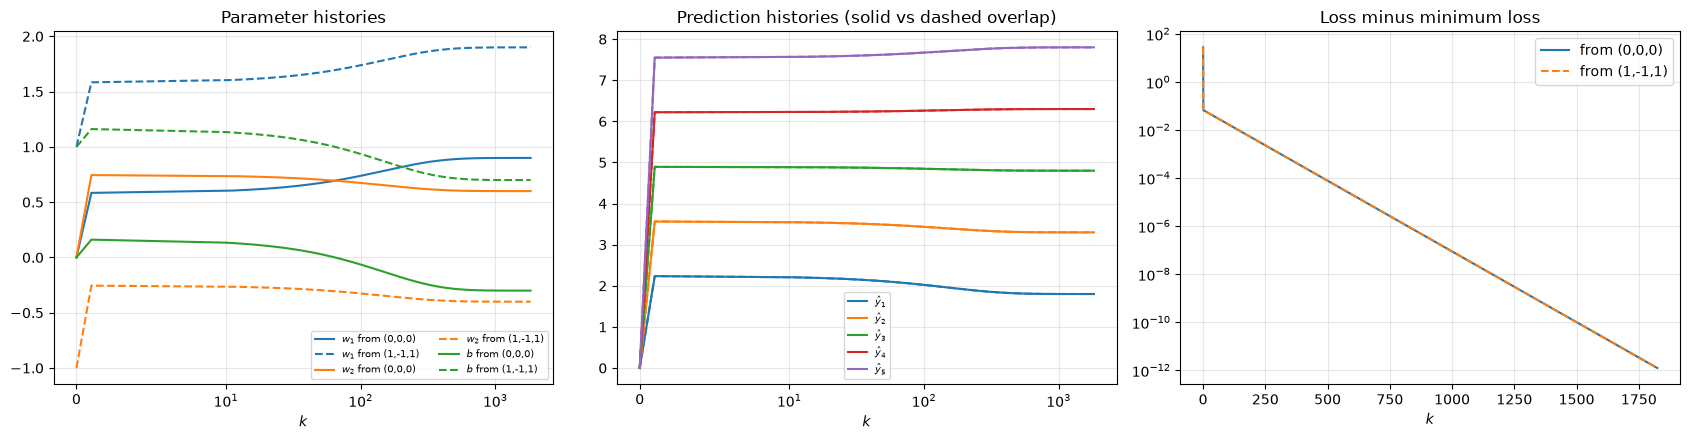

In [21]:
rB = converge(L2, G2, [1.0, -1.0, 1.0], eta3)
thB = rB["x"][-1]
rows = []
for name, rr, th in [("from (0,0,0)", rA, thA), ("from (1,−1,1)", rB, thB)]:
    rows.append([name, f"{eta3:.7f}", f"{th[0]:.9f}", f"{th[1]:.9f}", f"{th[2]:.9f}",
                 f"{rr['loss'][-1]:.13f}", sci(rr["grad_norm"][-1]), rr["n_updates"], rr["status"]])
d = thB - thA
rows.append(["**difference**", "", f"{d[0]:.6f}", f"{d[1]:.6f}", f"{d[2]:.6f}",
             sci(abs(rB["loss"][-1] - rA["loss"][-1])), "", "", ""])
md_table(["run", "η", "w₁", "w₂", "b", "MSE", "‖∇L‖", "updates", "status"], rows)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
names = ["$w_1$", "$w_2$", "$b$"]
for j, c in enumerate(["tab:blue", "tab:orange", "tab:green"]):
    axs[0].plot(rA["x"][:, j], "-", color=c, label=names[j] + " from (0,0,0)")
    axs[0].plot(rB["x"][:, j], "--", color=c, label=names[j] + " from (1,-1,1)")
axs[0].set_xscale("symlog", linthresh=10); axs[0].set_title("Parameter histories")
axs[0].set_xlabel("$k$"); axs[0].legend(fontsize=7, ncol=2); axs[0].grid(alpha=.3)
predA, predB = rA["x"] @ A2.T, rB["x"] @ A2.T
for i in range(n):
    axs[1].plot(predA[:, i], "-", color=f"C{i}", label=rf"$\hat y_{i + 1}$")
    axs[1].plot(predB[:, i], "--", color=f"C{i}")
axs[1].set_xscale("symlog", linthresh=10)
axs[1].set_title("Prediction histories (solid vs dashed overlap)")
axs[1].set_xlabel("$k$"); axs[1].legend(fontsize=7); axs[1].grid(alpha=.3)
gapA, gapB = rA["loss"] - mse_ref2, rB["loss"] - mse_ref2
axs[2].semilogy(np.where(gapA > 0, gapA, np.nan), "-", label="from (0,0,0)")
axs[2].semilogy(np.where(gapB > 0, gapB, np.nan), "--", label="from (1,-1,1)")
axs[2].set_title("Loss minus minimum loss"); axs[2].set_xlabel("$k$")
axs[2].legend(); axs[2].grid(alpha=.3, which="both")
save(fig, "p3b_histories.png")

The two runs end at **different coefficients**, which differ by exactly $(1,-1,1)$, but their **predictions and loss curves are the same**.

This is what the reduced model from 3B.1 predicts: the difference $(1,-1,1)$ does not change $\alpha$ or $\beta$, so both runs see the same residuals and take the same steps. The second result is **not** a wrong fit: it has the same predictions and the same minimal loss as the reference, so it is an equally good solution. The zero eigenvalue of $H$ means the loss is completely flat in the direction $(1,-1,1)$, so there is no unique minimizer.

#### Task 3B.4: Visualizing the fit

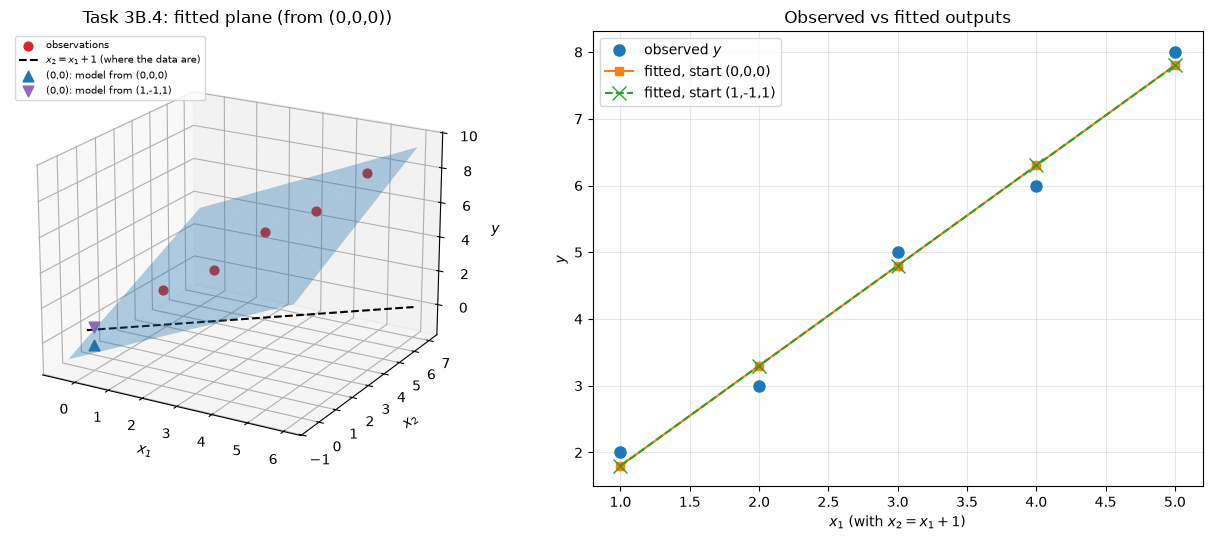

| model | prediction at (x₁, x₂) = (0, 0) |
|---|---|
| from (0,0,0) | -0.299998 |
| from (1,−1,1) | 0.700002 |

In [22]:
fig = plt.figure(figsize=(13, 5.5))
ax3 = fig.add_subplot(1, 2, 1, projection="3d")
g1_, g2_ = np.meshgrid(np.linspace(-0.5, 6, 20), np.linspace(-0.5, 7, 20))
ax3.plot_surface(g1_, g2_, thA[0] * g1_ + thA[1] * g2_ + thA[2], alpha=.35, color="tab:blue")
ax3.scatter(X1, X2, Y2, color="tab:red", s=40, depthshade=False, label="observations")
ll = np.linspace(-0.5, 6, 2)
ax3.plot(ll, ll + 1, 0 * ll, "k--", label="$x_2=x_1+1$ (where the data are)")
ax3.scatter([0], [0], [thA[2]], color="tab:blue", marker="^", s=60, label="(0,0): model from (0,0,0)")
ax3.scatter([0], [0], [thB[2]], color="tab:purple", marker="v", s=60, label="(0,0): model from (1,-1,1)")
ax3.set_xlabel("$x_1$"); ax3.set_ylabel("$x_2$"); ax3.set_zlabel("$y$")
ax3.set_title("Task 3B.4: fitted plane (from (0,0,0))"); ax3.legend(fontsize=7, loc="upper left")
ax3.view_init(elev=20, azim=-60)
ax = fig.add_subplot(1, 2, 2)
ax.plot(X1, Y2, "o", ms=8, label="observed $y$")
ax.plot(X1, A2 @ thA, "s-", label="fitted, start (0,0,0)")
ax.plot(X1, A2 @ thB, "x--", ms=10, label="fitted, start (1,-1,1)")
ax.set_xlabel("$x_1$ (with $x_2=x_1+1$)"); ax.set_ylabel("$y$"); ax.set_title("Observed vs fitted outputs")
ax.legend(); ax.grid(alpha=.3)
save(fig, "p3b_fit.png")

x_new = np.array([0.0, 0.0, 1.0])            # input (0, 0) plus the intercept
md_table(["model", "prediction at (x₁, x₂) = (0, 0)"],
         [["from (0,0,0)", f"{x_new @ thA:.6f}"], ["from (1,−1,1)", f"{x_new @ thB:.6f}"]])

All observations lie on the line $x_2=x_1+1$ in the input plane, so the data only cover a line, not a 2D region. The fitted plane is pinned down along that line, but its tilt away from the line is not determined by the data.

At $(0,0)$, which is off that line, the two models give $-0.3$ and $0.7$. Agreeing on the training inputs does not mean agreeing elsewhere. Since there is no target value at $(0,0)$, neither prediction can be called more accurate.

| Question | Answer for Dataset 2 |
|---|---|
| Does the loss converge? | Yes, to 0.06, from both starts. |
| Do the parameters converge? | Yes, each run settles on a definite vector. |
| Is that vector unique? | No, it depends on the starting point. |

---
## Synthesis

The learning rate and the curvature always act together. What decides the behavior is the factor $1-\eta\lambda$ by which the error is multiplied at each step, where $\lambda$ is a curvature (Hessian eigenvalue). If this factor is between 0 and 1 the iterates approach the minimum steadily; between −1 and 0 they oscillate around it but still converge; at −1 they bounce forever; beyond that they diverge. This is why $\eta=0.1$ worked in Problems 1 and 2, where the curvature is 2, but failed on Dataset 1, where it is about 23.7.

The starting point did not change the minimum in Problems 1 and 2, only the path and the number of updates. Oscillations can happen while the loss still decreases, because the loss depends on the distance to the minimum, not on which side we are on.

Dataset 2 shows that a converging loss and converging parameters do not mean the answer is unique. Because $x_2=x_1+1$, one direction in parameter space has zero curvature, gradient descent never moves along it, and the final coefficients depend on where we started.